<a href="https://colab.research.google.com/github/Tanuja-code125/Applied-ML-Lab/blob/main/ML_Exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction — Simple Linear Regression

**Dataset:** `Housing.csv` (columns: `area`, `price`)

This notebook walks through a complete, minimal pipeline:
1. Import data
2. Basic preprocessing
3. Visualize the data (scatter plot)
4. Train/test split
5. Train a Simple Linear Regression model
6. Report slope & intercept
7. Report accuracy metrics
8. Visualize the regression line
9. Predict price for a new area value

> **Note:** Since we're skipping feature management, this notebook uses a single feature (`area`) to predict `price`. If This CSV has more numeric columns, this same pipeline still works

#**Step 0: Install & Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#**Step 1: Import the Data**
On Google Colab, upload Housing.csv first. Run the cell below — it will open a file picker.

In [ ]:
# Load the dataset
df = pd.read_csv("Housing.csv")

# Quick look at the data
print("Shape:", df.shape)
print(df.head())
print(df.describe())
print(df.info())

Shape: (545, 7)
      price  area  bedrooms  bathrooms  stories mainroad guestroom
0  13300000  7420         4          2        3      yes        no
1  12250000  8960         4          4        4      yes        no
2  12250000  9960         3          2        2      yes        no
3  12215000  7500         4          2        2      yes        no
4  11410000  7420         4          1        2      yes       yes
              price          area    bedrooms   bathrooms     stories
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000
mean   4.766729e+06   5150.541284    2.965138    1.286239    1.805505
std    1.870440e+06   2170.141023    0.738064    0.502470    0.867492
min    1.750000e+06   1650.000000    1.000000    1.000000    1.000000
25%    3.430000e+06   3600.000000    2.000000    1.000000    1.000000
50%    4.340000e+06   4600.000000    3.000000    1.000000    2.000000
75%    5.740000e+06   6360.000000    3.000000    2.000000    2.000000
max    1.330000e+07  1

#**Step 2: Basic Data Preprocessing**
We'll do the essentials only:

Check for missing values
Check data types
Basic descriptive statistics
Select the columns we need (area as feature, price as target)
Drop duplicates / missing rows if any

In [ ]:
# Check info and missing values
print("\nMissing values per column:\n", df.isnull().sum())
# Keep only the columns needed for this simple regression
data = df[['area', 'price']].copy()

# Drop any missing or duplicate rows
data = data.dropna()
data = data.drop_duplicates()

print("Final shape after cleaning:", data.shape)
data.head()

#Step 3: Visualize the Data (Scatter Plot)

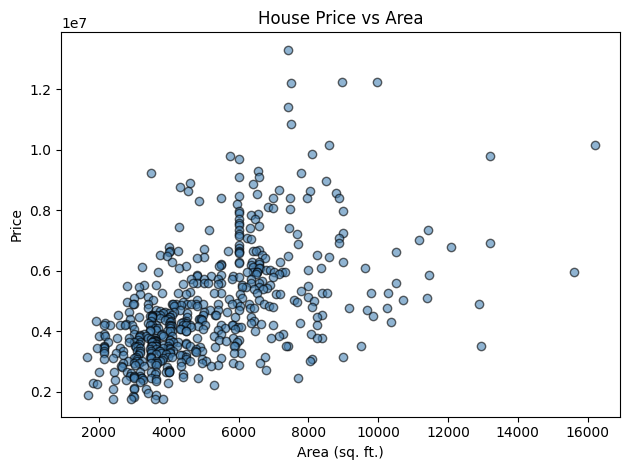

In [ ]:
plt.scatter(data['area'], data['price'], color='steelblue', alpha=0.6, edgecolor='k')
plt.title('House Price vs Area')
plt.xlabel('Area (sq. ft.)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

#**Step 4: Train-Test Split**
We split the data into training (80%) and testing (20%) sets.

In [ ]:
X = data[['area']]   # Feature (kept as 2D DataFrame for sklearn)
y = data['price']     # Target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print(X_train.head())
print(y_train.head())

Training samples: 399
Testing samples : 133
     area
519  4840
202  4120
427  2145
19   6420
398  3120
519    2450000
202    4900000
427    3332000
19     8855000
398    3500000
Name: price, dtype: int64


#**Step 5: Train the Linear Regression**




In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


#**Step 6: Slope and Intercept**
For simple linear regression: price = slope * area + intercept

In [ ]:
slope = model.coef_[0]
intercept = model.intercept_

print(f"Slope (coefficient)  : {slope:.4f}")
print(f"Intercept             : {intercept:.4f}")
print(f"\nEquation: price = {slope:.4f} * area + ({intercept:.4f})")

Slope (coefficient)  : 441.5876
Intercept             : 2450352.7349

Equation: price = 441.5876 * area + (2450352.7349)


#**Step 7: Accuracy Metrics**

##We evaluate the model on the test set using:

MAE (Mean Absolute Error)
MSE (Mean Squared Error)
RMSE (Root Mean Squared Error)
R² Score (coefficient of determination — how well the model explains variance in price)

In [ ]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)  : {mae:,.2f}")
print(f"Mean Squared Error (MSE)   : {mse:,.2f}")
print(f"Root Mean Squared Error    : {rmse:,.2f}")
print(f"R² Score                   : {r2:.4f}")

Mean Absolute Error (MAE)  : 1,424,905.44
Mean Squared Error (MSE)   : 3,547,685,936,845.33
Root Mean Squared Error    : 1,883,530.18
R² Score                   : 0.2770


#**Step 8: Visualize the Regression Line**



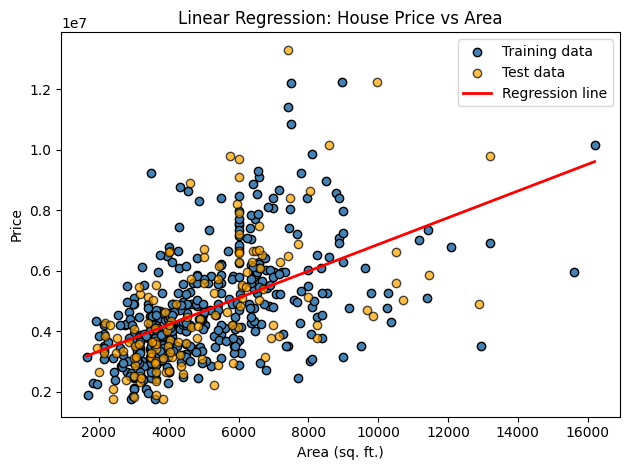

In [ ]:
plt.scatter(X_train, y_train, color='steelblue', alpha=1, edgecolor='k', label='Training data')
plt.scatter(X_test, y_test, color='orange', alpha=0.7, edgecolor='k', label='Test data')

# Regression line across the full range of area values
x_range = np.linspace(data['area'].min(), data['area'].max(), 100).reshape(-1, 1)
y_range_pred = model.predict(pd.DataFrame(x_range, columns=['area']))

plt.plot(x_range, y_range_pred, color='red', linewidth=2, label='Regression line')

plt.title('Linear Regression: House Price vs Area')
plt.xlabel('Area (sq. ft.)')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

#**Step 9: Predict Price for a New House**
*Use the trained model to predict the price of a house given its area.*

In [ ]:
def predict_price(area_value):
    """Predict house price given an area (in sq. ft.) using the trained model."""
    input_df = pd.DataFrame([[area_value]], columns=['area'])
    predicted_price = model.predict(input_df)[0]
    return predicted_price

# Example usage
new_area = 3000   # change this value to any area you want to test
predicted = predict_price(new_area)
print(f"Predicted price for area = {new_area} sq. ft. : {predicted:,.2f}")

Predicted price for area = 3000 sq. ft. : 3,775,115.53


---
### Summary
- Trained a simple linear regression model on `area` → `price`.
- Reported slope, intercept, and evaluation metrics (MAE, MSE, RMSE, R²).
- Visualized both the raw data and the fitted regression line.
- Provided a reusable `predict_price()` function for new predictions.



#**House Price Prediction — Multiple Linear Regression**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#**Step 1: Import the Data**
On Google Colab, upload Housing.csv first. Run the cell below — it will open a file picker.

In [ ]:
# Load the dataset
df = pd.read_csv("Housing.csv")

# Quick look at the data
print("Shape:", df.shape)
print(df.head())
print(df.describe())
print(df.info())

FileNotFoundError: [Errno 2] No such file or directory: 'Housing.csv'

#**Step 2: Basic Data Preprocessing**
We'll do the essentials only:

Check for missing values
Check data types
Basic descriptive statistics
Select the columns we need (area as feature, price as target)
Drop duplicates / missing rows if any

In [ ]:
df = pd.read_csv("Housing.csv")

# Check info and missing values
print("\nMissing values per column:\n", df.isnull().sum())
# Keep only the columns needed for this multiple regression
features=[['area', 'bedrooms', 'bathrooms', 'stories', 'parking',]]
target = 'price' # Define target explicitly

# Correctly select features and target columns
data = df[features + [target]].copy()

# Drop any missing or duplicate rows
data = data.dropna()
data = data.drop_duplicates()

print("Final shape after cleaning:", data.shape)
data.head()

NameError: name 'pd' is not defined